In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 导入数据集
errors  = pd.read_csv('./datasets/PdM_errors.csv')
failures = pd.read_csv('./datasets/PdM_failures.csv')
machines = pd.read_csv('./datasets/PdM_machines.csv')
dM_maint = pd.read_csv('./datasets/PdM_maint.csv')
telemetry = pd.read_csv('./datasets/PdM_telemetry.csv')

# Summary

## errors

In [3]:
errors.head()

,datetime,machineID,errorID
0,2015-01-03 07:00:00,1,error1
1,2015-01-03 20:00:00,1,error3
2,2015-01-04 06:00:00,1,error5
3,2015-01-10 15:00:00,1,error4
4,2015-01-22 10:00:00,1,error4


In [4]:
errors['datetime'] = pd.to_datetime(errors['datetime'], format='%Y-%m-%d %H:%M:%S')
errors = errors.sort_values(by=['machineID', 'datetime', 'errorID']).reset_index(drop=True)
errors.head()

,datetime,machineID,errorID
0,2015-01-03 07:00:00,1,error1
1,2015-01-03 20:00:00,1,error3
2,2015-01-04 06:00:00,1,error5
3,2015-01-10 15:00:00,1,error4
4,2015-01-22 10:00:00,1,error4


其余数据集按照相同方式处理

## Telemetry

In [5]:
telemetry.head()

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511


In [6]:
telemetry['datetime'] = pd.to_datetime(telemetry['datetime'], format='%Y-%m-%d %H:%M:%S')
telemetry = telemetry.sort_values(by=['machineID', 'datetime']).reset_index(drop=True)
telemetry.head()

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511


In [7]:
telemetry.select_dtypes(include=['number']).describe()

,machineID,volt,rotate,pressure,vibration
count,876100.000000,876100.000000,876100.000000,876100.000000,876100.000000
mean,50.500000,170.777736,446.605119,100.858668,40.385007
std,28.866087,15.509114,52.673886,11.048679,5.370361
min,1.000000,97.333604,138.432075,51.237106,14.877054
25%,25.750000,160.304927,412.305714,93.498181,36.777299
50%,50.500000,170.607338,447.558150,100.425559,40.237247
75%,75.250000,181.004493,482.176600,107.555231,43.784938
max,100.000000,255.124717,695.020984,185.951998,76.791072


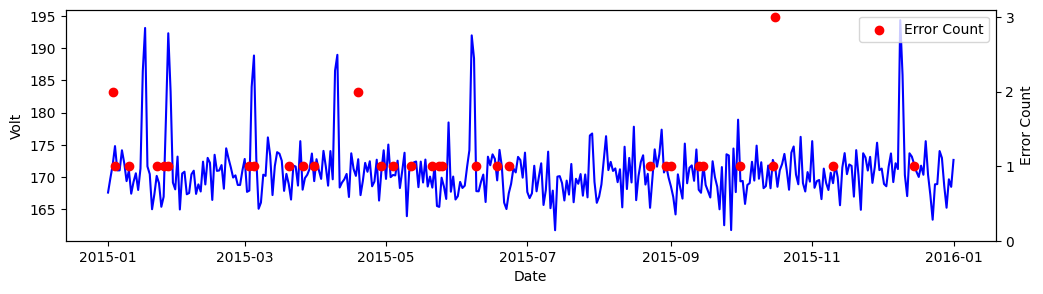

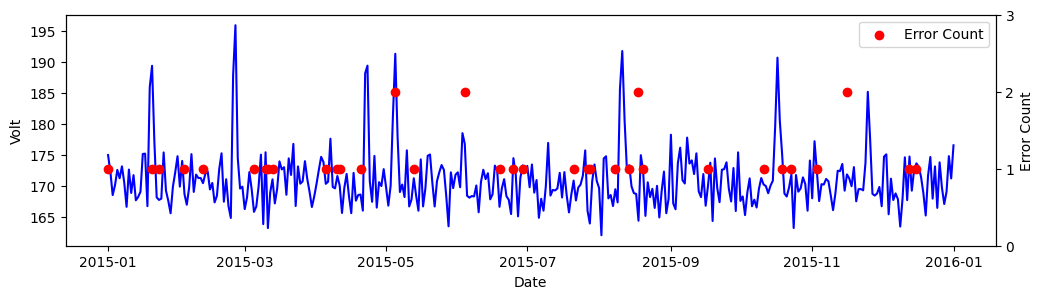

In [8]:
def volt_vs_error(machine_id):
    # volt
    telemetry['date'] = telemetry['datetime'].dt.date
    telemetry_per_day = telemetry.groupby(['machineID', 'date']).mean().reset_index()
    telemetry_per_day = telemetry_per_day[telemetry_per_day['machineID'] == machine_id]

    # errors
    errors['date'] = errors['datetime'].dt.date
    errors_per_day = errors.groupby(['machineID', 'date']).size().reset_index().rename(columns={0: 'error_count'})
    errors_per_day = errors_per_day[errors_per_day['machineID'] == machine_id] 

    # plot
    fig, ax1 = plt.subplots(figsize=(12, 3))
    ax1.plot(telemetry_per_day['date'], telemetry_per_day['volt'], label='Volt', color='blue')
    ax1.set_xlabel('Date')
    ax1.set_ylabel('Volt')

    ax2 = ax1.twinx()
    ax2.scatter(errors_per_day['date'], errors_per_day['error_count'], label='Error Count', color='red')
    ax2.set_ylabel('Error Count')
    plt.yticks(np.arange(0,4))

    plt.grid(visible=False)
    plt.legend()
    plt.show()


# 1号机的时间序列+故障散点图
volt_vs_error(1)

# 42号机的时间序列+故障散点图
volt_vs_error(42)

电压的异常波动似乎与故障的发生没有关联，而且异常电压出现的时间不同的机器似乎不同

## Feature Engineering

In [9]:
# 按照3h的间隔重新采样，并计算每个时间段的平均值
temp = []
fields = ['volt', 'rotate', 'pressure', 'vibration']
for col in fields:
    temp.append(pd.pivot_table(telemetry,
                               index='datetime',
                               columns='machineID',
                               values=col)
                               .resample('3h', closed='left', label='right')
                               .mean()
                               .unstack())

telemetry_mean_3h = pd.concat(temp, axis=1)
telemetry_mean_3h.columns = [i + 'mean_3h' for i in fields]
telemetry_mean_3h.reset_index(inplace=True)

In [10]:
# 按照3h的间隔重新采样，并计算每个时间段的标准差
temp = []
fields = ['volt', 'rotate', 'pressure', 'vibration']
for col in fields:
    temp.append(pd.pivot_table(telemetry,
                               index='datetime',
                               columns='machineID',
                               values=col)
                               .resample('3h', closed='left', label='right')
                               .std()
                               .unstack())

telemetry_std_3h = pd.concat(temp, axis=1)
telemetry_std_3h.columns = [i + 'std_3h' for i in fields]
telemetry_std_3h.reset_index(inplace=True)

In [11]:
# 计算每个时间点前24小时的滚动平均值
temp = []
fields = ['volt', 'rotate', 'pressure', 'vibration']
for col in fields:
    temp.append(pd.pivot_table(telemetry,
                            index='datetime',
                            columns='machineID',
                            values=col)
                            .rolling('24h', min_periods=1)
                            .mean()
                            .resample('3h', closed='left', label='right')
                            .last()
                            .unstack())
    
telemetry_rolling_mean_24h = pd.concat(temp, axis=1)
telemetry_rolling_mean_24h.columns = [i + 'rolling_mean_24h' for i in fields]
telemetry_rolling_mean_24h.reset_index(inplace=True)

In [12]:
# 计算每个时间点前24小时的滚动标准差值
temp = []
fields = ['volt', 'rotate', 'pressure', 'vibration']
for col in fields:
    temp.append(pd.pivot_table(telemetry,
                            index='datetime',
                            columns='machineID',
                            values=col)
                            .rolling('24h', min_periods=1)
                            .std()
                            .resample('3h', closed='left', label='right')
                            .last()
                            .unstack())
    
telemetry_rolling_std_24h = pd.concat(temp, axis=1)
telemetry_rolling_std_24h.columns = [i + 'rolling_std_24h' for i in fields]
telemetry_rolling_std_24h.reset_index(inplace=True)

In [13]:
telemetry_features = pd.merge(telemetry_mean_3h, telemetry_std_3h, on=['machineID', 'datetime'], how='left')
telemetry_features = pd.merge(telemetry_features, telemetry_rolling_mean_24h, on=['machineID', 'datetime'], how='left')
telemetry_features = pd.merge(telemetry_features, telemetry_rolling_std_24h, on=['machineID', 'datetime'], how='left')
telemetry_features.iloc[:,2:].describe()

,voltmean_3h,rotatemean_3h,pressuremean_3h,vibrationmean_3h,voltstd_3h,rotatestd_3h,pressurestd_3h,vibrationstd_3h,voltrolling_mean_24h,rotaterolling_mean_24h,pressurerolling_mean_24h,vibrationrolling_mean_24h,voltrolling_std_24h,rotaterolling_std_24h,pressurerolling_std_24h,vibrationrolling_std_24h
count,292100.000000,292100.000000,292100.000000,292100.000000,292000.000000,292000.000000,292000.000000,292000.000000,292100.000000,292100.000000,292100.000000,292100.000000,292100.000000,292100.000000,292100.000000,292100.000000
mean,170.778609,446.603743,100.858983,40.385180,13.299090,44.456338,8.885976,4.441164,170.778189,446.604036,100.859231,40.384655,14.916839,49.945229,10.046949,5.002047
std,9.504636,33.139576,7.416963,3.479687,6.965914,23.216712,4.656211,2.320302,4.731906,18.099836,4.748859,2.063574,2.266807,7.711572,1.716097,0.801569
min,125.532506,211.811184,72.118639,26.569635,0.025509,0.078991,0.027417,0.015278,147.757049,267.008131,82.983398,32.504517,1.101184,3.590072,0.893261,0.852475
25%,164.449465,427.552297,96.238330,38.147563,8.027455,26.903705,5.370581,2.684790,168.068272,441.561897,98.669579,39.356771,13.355042,44.662665,8.923782,4.460849
50%,170.435196,448.380810,100.234420,40.145855,12.495658,41.794719,8.346020,4.173955,170.211338,449.194872,100.098506,40.070429,14.854665,49.613900,9.922115,4.958264
75%,176.613713,468.452496,104.407388,42.228094,17.688490,59.104130,11.790303,5.900106,172.457962,456.372822,101.615623,40.832710,16.396192,54.807898,10.982000,5.484825
max,241.420717,586.682904,162.309656,69.311324,58.444332,179.903039,35.659369,18.305595,220.569064,503.806432,152.660905,61.852838,37.259561,133.923594,28.867737,12.609035


In [27]:
error_count = pd.get_dummies(errors, columns=['errorID'], dtype=int).drop(columns=['date'])

error_count = telemetry[['machineID', 'datetime']].merge(error_count, on=['machineID', 'datetime'], how='left').fillna(0)

error_count.head()

,machineID,datetime,errorID_error1,errorID_error2,errorID_error3,errorID_error4,errorID_error5
0,1,2015-01-01 06:00:00,0.0,0.0,0.0,0.0,0.0
1,1,2015-01-01 07:00:00,0.0,0.0,0.0,0.0,0.0
2,1,2015-01-01 08:00:00,0.0,0.0,0.0,0.0,0.0
3,1,2015-01-01 09:00:00,0.0,0.0,0.0,0.0,0.0
4,1,2015-01-01 10:00:00,0.0,0.0,0.0,0.0,0.0


In [31]:
temp = []

fields = ['errorID_error%d' % i for i in range(1, 6)]
for col in fields:
    temp.append(pd.pivot_table(error_count,
                               index='datetime',
                               columns='machineID',
                               values=col)
                               .rolling('24h', min_periods=1)
                               .max()
                               .resample('3h', closed='left', label='right')
                               .max()
                               .unstack())
    
error_count = pd.concat(temp, axis=1)
error_count.columns = [i + '_count' for i in fields]
error_count.reset_index(inplace=True)
error_count.head()

,machineID,datetime,errorID_error1_count,errorID_error2_count,errorID_error3_count,errorID_error4_count,errorID_error5_count
0,1,2015-01-01 09:00:00,0.0,0.0,0.0,0.0,0.0
1,1,2015-01-01 12:00:00,0.0,0.0,0.0,0.0,0.0
2,1,2015-01-01 15:00:00,0.0,0.0,0.0,0.0,0.0
3,1,2015-01-01 18:00:00,0.0,0.0,0.0,0.0,0.0
4,1,2015-01-01 21:00:00,0.0,0.0,0.0,0.0,0.0
